In [3]:
print("Importing...")
import sys
%load_ext autoreload
%autoreload 2
sys.path.insert(
    0,
    "/glade/u/home/manishrv/documents/nwa12_0.1/regional_mom_workflows/CrocoDash/CrocoDash/rm6",
)
import regional_mom6 as rm6
from regional_mom6.utils import ap2ep, ep2ap
import xarray as xr
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import xesmf as xe


Importing...


In [4]:
hgrid = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/2n3b.nwa-three-boundary-new-regridding/hgrid.nc")
ua = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/temp_ua.nc")
coords = rm6.regridding.coords(hgrid, "north", "segment_002")
# Isolate the northern boundary, plot against the mask
tidal_data_given_angle = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/forcing/tu_segment_002.nc")
tidal_data_fred = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/fred_average/forcing/tu_segment_002.nc")
tidal_data_keith = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/keith_double_regridding/forcing/tu_segment_002.nc")

forcing_data_given_angle = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/forcing_obc_segment_002.nc")
forcing_data_fred= xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/fred_average/forcing_obc_segment_002.nc")
forcing_data_keith = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/keith_double_regridding/forcing_obc_segment_002.nc")

bathy = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/2n3b.nwa-three-boundary-new-regridding/bathymetry.nc")


2024-12-10 11:11:21,007 - regional_mom6.regridding.coords - INFO - Creating coordinates of the boundary q/u/v points


In [42]:
angles_og = rm6.regridding.initialize_hgrid_rotation_angles_using_pseudo_hgrid(hgrid)
angles_og.values

array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [4.4582023 , 4.46796407, 4.48729468, ..., 4.39013437, 4.37343077,
        4.36519006],
       [4.46869764, 4.47848207, 4.4978571 , ..., 4.40025037, 4.38351466,
        4.37525847],
       [4.47477904, 4.48901512, 4.50843463, ..., 4.41038013, 4.39361227,
        4.38186368]])

In [43]:
angles_new = rm6.regridding.initialize_hgrid_rotation_angles_using_pseudo_hgrid_2(hgrid)
angles_new.values

2024-12-10 11:49:15,837 - regional_mom6.regridding.mom6_angle_calculation_method - INFO - Calculating grid rotation angle


array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [4.4582023 , 4.46796407, 4.48729468, ..., 4.39013437, 4.37343077,
        4.36519006],
       [4.46869764, 4.47848207, 4.4978571 , ..., 4.40025037, 4.38351466,
        4.37525847],
       [4.47477904, 4.48901512, 4.50843463, ..., 4.41038013, 4.39361227,
        4.38186368]])

In [44]:
np.where((angles_og == angles_new )== False)


(array([], dtype=int64), array([], dtype=int64))

In [50]:
(angles_new.values - angles_og.values).max()

0.0

Text(0.5, 1.0, 'NWA12 mesh (every 10 points)')

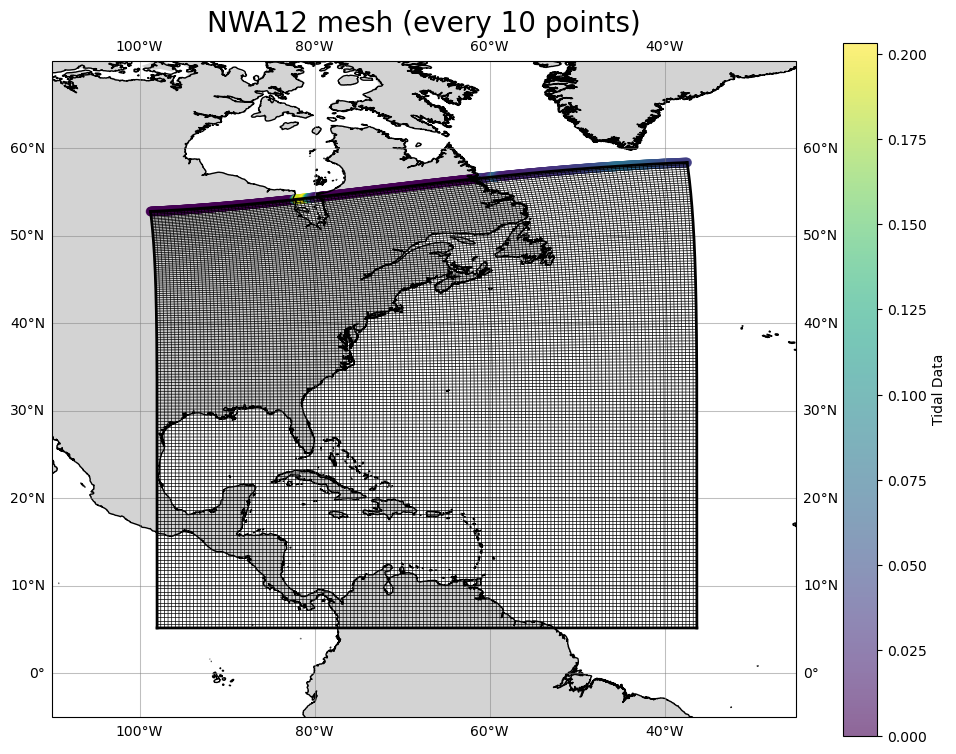

In [8]:
# Plot and save the NWA12 Mesh grid

plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)

k=10
ax.plot(hgrid.x[::k,::k], hgrid.y[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
ax.plot(hgrid.x[::k,::k].T, hgrid.y[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

ax.plot(hgrid.x[0,:], hgrid.y[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[-1,:], hgrid.y[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,0], hgrid.y[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,-1], hgrid.y[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
scatter = ax.scatter(tidal_data_given_angle.lon_segment_002.values, tidal_data_given_angle.lat_segment_002.values, c= tidal_data_given_angle.uamp_segment_002[0][0], cmap='viridis', transform=ccrs.PlateCarree(), alpha=0.6)
plt.colorbar(scatter, ax=ax, orientation='vertical', label='Tidal Data')

plt.title('NWA12 mesh (every {} points)'.format(k), fontsize=20)



Text(0.5, 1.0, 'NWA12 mesh (every 10 points)')

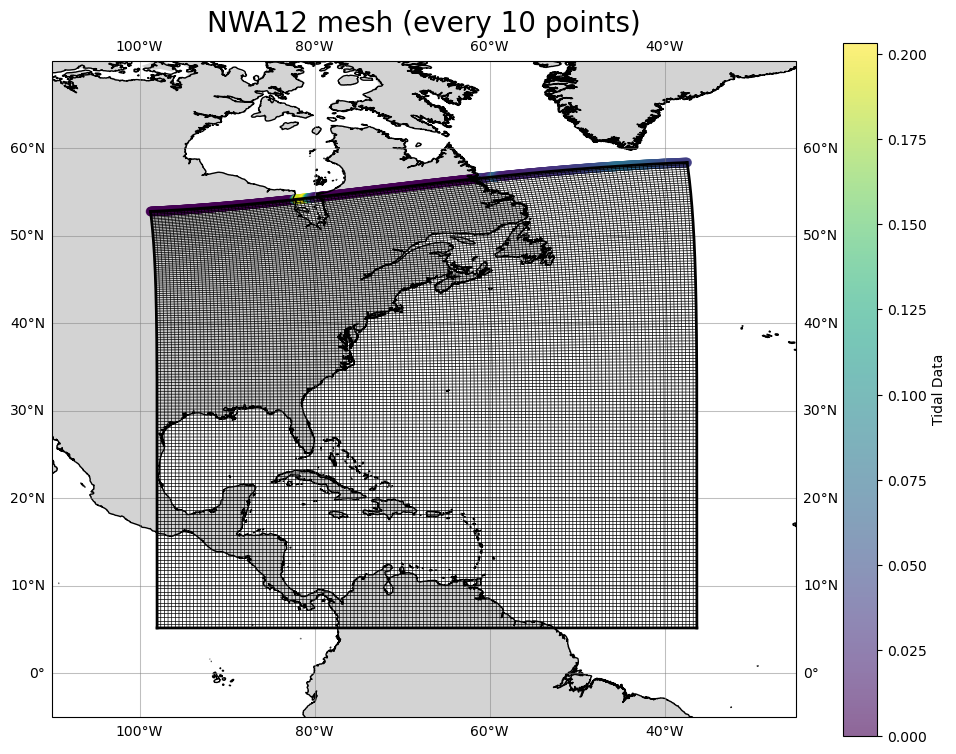

In [9]:
# Plot and save the NWA12 Mesh grid

plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)

k=10
ax.plot(hgrid.x[::k,::k], hgrid.y[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
ax.plot(hgrid.x[::k,::k].T, hgrid.y[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

ax.plot(hgrid.x[0,:], hgrid.y[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[-1,:], hgrid.y[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,0], hgrid.y[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,-1], hgrid.y[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
scatter = ax.scatter(tidal_data_fred.lon_segment_002.values, tidal_data_fred.lat_segment_002.values, c= tidal_data_fred.uamp_segment_002[0][0], cmap='viridis', transform=ccrs.PlateCarree(), alpha=0.6)
plt.colorbar(scatter, ax=ax, orientation='vertical', label='Tidal Data')

plt.title('NWA12 mesh (every {} points)'.format(k), fontsize=20)


Text(0.5, 1.0, 'NWA12 mesh (every 10 points)')

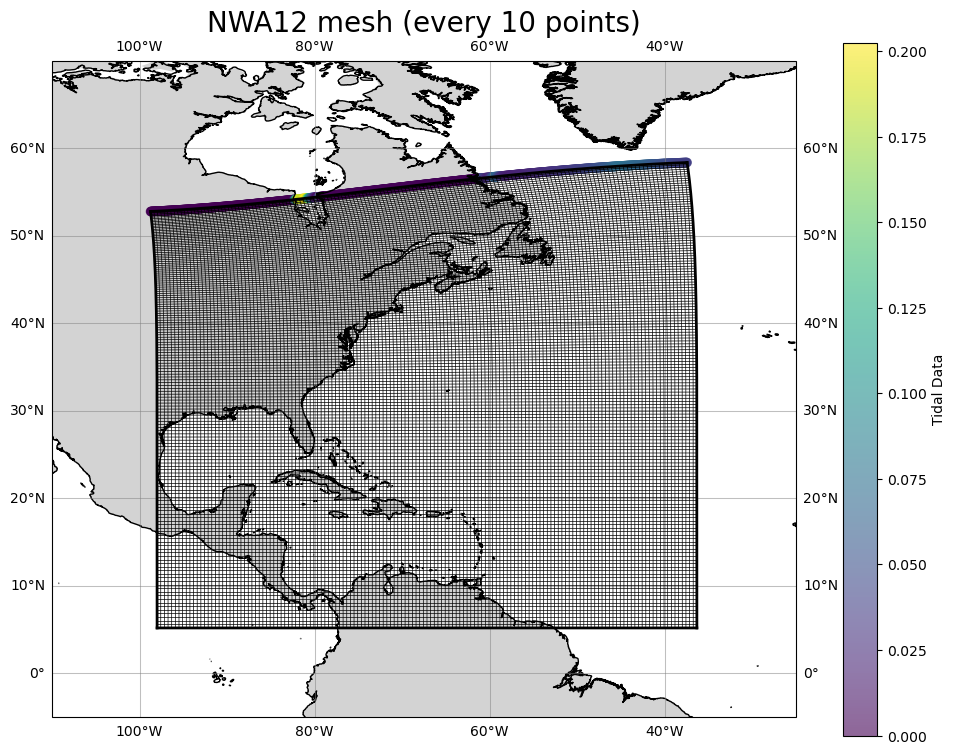

In [10]:
# Plot and save the NWA12 Mesh grid

plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)

k=10
ax.plot(hgrid.x[::k,::k], hgrid.y[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
ax.plot(hgrid.x[::k,::k].T, hgrid.y[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

ax.plot(hgrid.x[0,:], hgrid.y[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[-1,:], hgrid.y[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,0], hgrid.y[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,-1], hgrid.y[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
scatter = ax.scatter(tidal_data_keith.lon_segment_002.values, tidal_data_keith.lat_segment_002.values, c= tidal_data_keith.uamp_segment_002[0][0], cmap='viridis', transform=ccrs.PlateCarree(), alpha=0.6)
plt.colorbar(scatter, ax=ax, orientation='vertical', label='Tidal Data')

plt.title('NWA12 mesh (every {} points)'.format(k), fontsize=20)


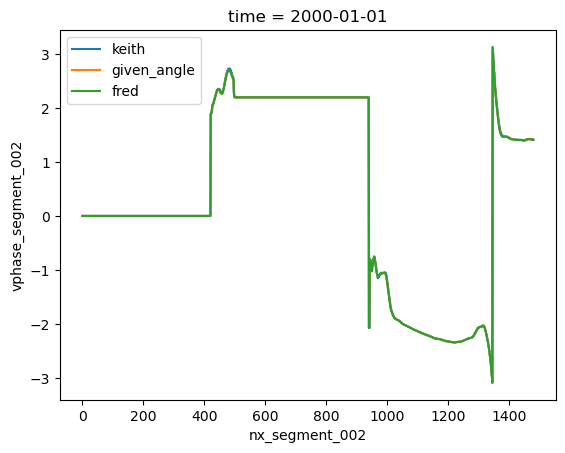

In [ ]:
tidal_data_keith.vphase_segment_002[0][0].plot(label = "keith")
tidal_data_given_angle.vphase_segment_002[0][0].plot(label="given_angle")
tidal_data_fred.vphase_segment_002[0][0].plot(label="fred")
plt.legend()

In [23]:
tidal_data_given_angle.uamp_segment_002[0][0].data == tidal_data_fred.uamp_segment_002[0][0].data

array([[ True,  True,  True, ...,  True,  True,  True]])

In [24]:
tidal_data_keith

<xarray.Dataset> Size: 261kB
Dimensions:             (time: 1, constituent: 10, ny_segment_002: 1,
                         nx_segment_002: 1481)
Coordinates:
    lon_segment_002     (nx_segment_002) float64 12kB -98.75 -98.71 ... -37.45
    lat_segment_002     (nx_segment_002) float64 12kB 52.78 52.78 ... 58.38
  * time                (time) datetime64[ns] 8B 2000-01-01
Dimensions without coordinates: constituent, ny_segment_002, nx_segment_002
Data variables:
    uamp_segment_002    (time, constituent, ny_segment_002, nx_segment_002) float32 59kB ...
    vamp_segment_002    (time, constituent, ny_segment_002, nx_segment_002) float32 59kB ...
    uphase_segment_002  (time, constituent, ny_segment_002, nx_segment_002) float32 59kB ...
    vphase_segment_002  (time, constituent, ny_segment_002, nx_segment_002) float32 59kB ...

Text(0.5, 1.0, 'NWA12 mesh (every 10 points)')

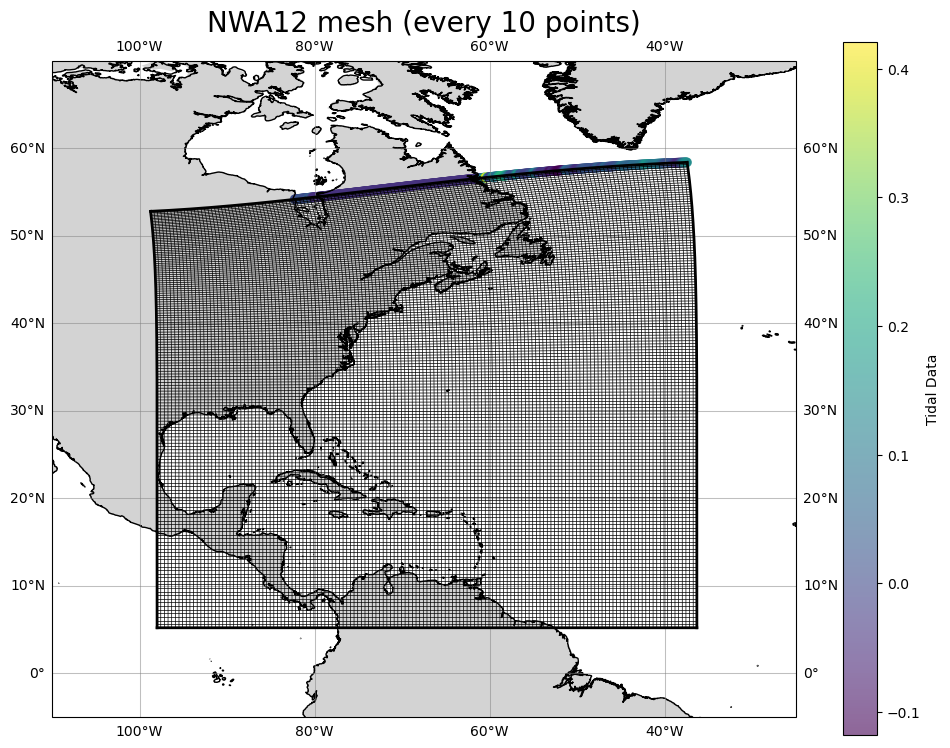

In [13]:
# Plot and save the NWA12 Mesh grid

plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)

k=10
ax.plot(hgrid.x[::k,::k], hgrid.y[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
ax.plot(hgrid.x[::k,::k].T, hgrid.y[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

ax.plot(hgrid.x[0,:], hgrid.y[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[-1,:], hgrid.y[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,0], hgrid.y[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,-1], hgrid.y[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
scatter = ax.scatter(tidal_data_given_angle.lon_segment_002.values, tidal_data_given_angle.lat_segment_002.values, c= forcing_data_given_angle.u_segment_002[0][0], cmap='viridis', transform=ccrs.PlateCarree(), alpha=0.6)
plt.colorbar(scatter, ax=ax, orientation='vertical', label='Tidal Data')

plt.title('NWA12 mesh (every {} points)'.format(k), fontsize=20)

Text(0.5, 1.0, 'NWA12 mesh (every 10 points)')

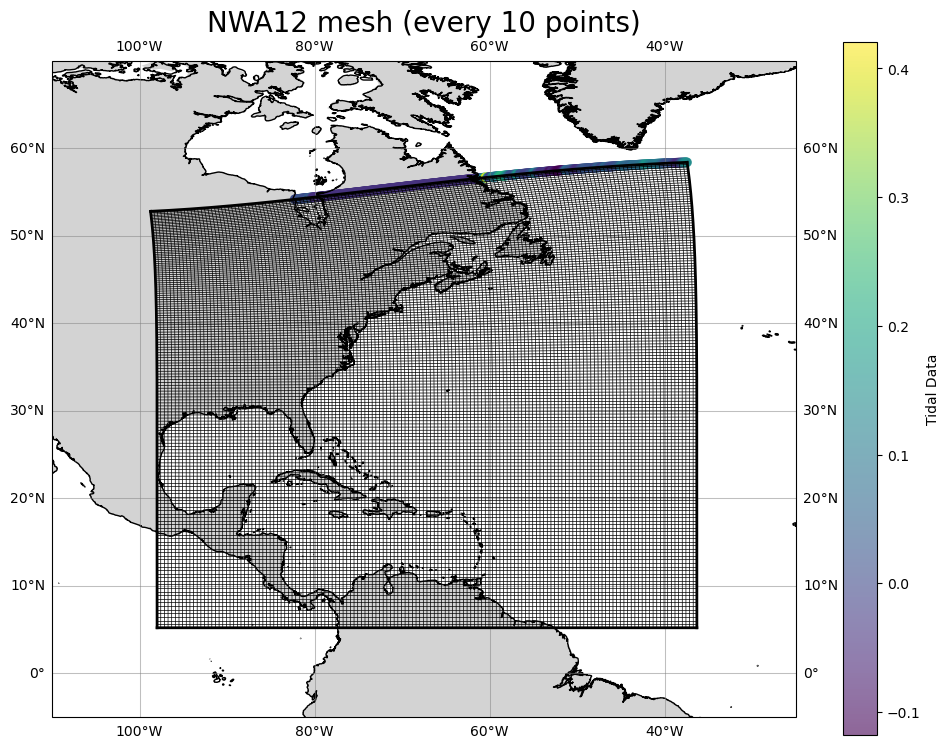

In [14]:
# Plot and save the NWA12 Mesh grid

plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)

k=10
ax.plot(hgrid.x[::k,::k], hgrid.y[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
ax.plot(hgrid.x[::k,::k].T, hgrid.y[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

ax.plot(hgrid.x[0,:], hgrid.y[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[-1,:], hgrid.y[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,0], hgrid.y[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,-1], hgrid.y[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
scatter = ax.scatter(tidal_data_given_angle.lon_segment_002.values, tidal_data_given_angle.lat_segment_002.values, c= forcing_data_fred.u_segment_002[0][0], cmap='viridis', transform=ccrs.PlateCarree(), alpha=0.6)
plt.colorbar(scatter, ax=ax, orientation='vertical', label='Tidal Data')

plt.title('NWA12 mesh (every {} points)'.format(k), fontsize=20)

Text(0.5, 1.0, 'NWA12 mesh (every 10 points)')

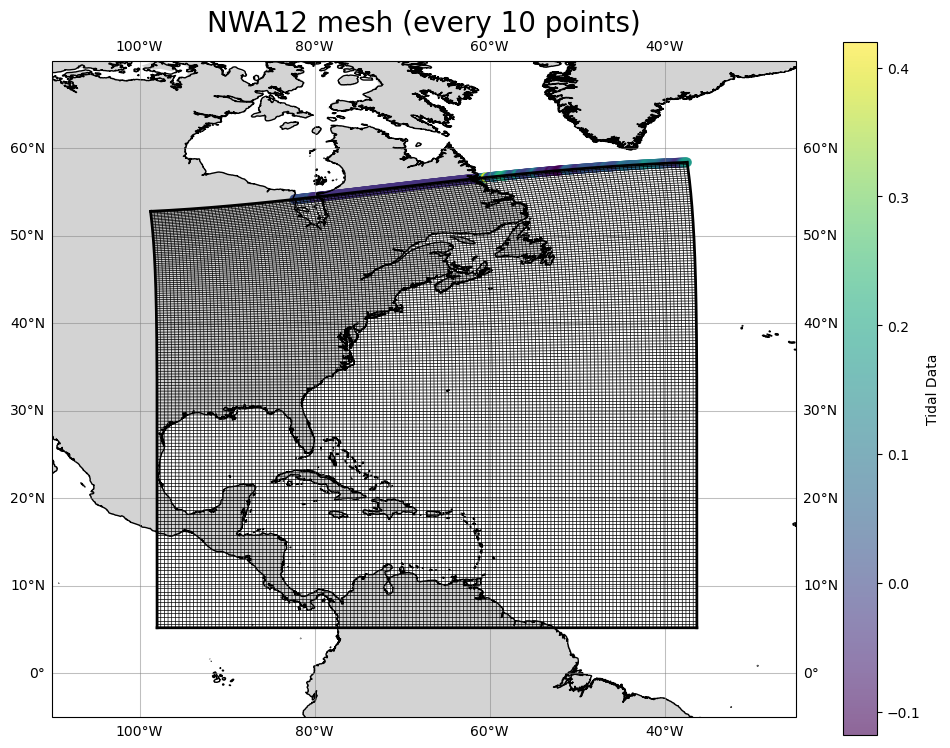

In [15]:
# Plot and save the NWA12 Mesh grid

plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)

k=10
ax.plot(hgrid.x[::k,::k], hgrid.y[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
ax.plot(hgrid.x[::k,::k].T, hgrid.y[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

ax.plot(hgrid.x[0,:], hgrid.y[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[-1,:], hgrid.y[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,0], hgrid.y[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,-1], hgrid.y[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
scatter = ax.scatter(tidal_data_given_angle.lon_segment_002.values, tidal_data_given_angle.lat_segment_002.values, c= forcing_data_keith.u_segment_002[0][0], cmap='viridis', transform=ccrs.PlateCarree(), alpha=0.6)
plt.colorbar(scatter, ax=ax, orientation='vertical', label='Tidal Data')

plt.title('NWA12 mesh (every {} points)'.format(k), fontsize=20)

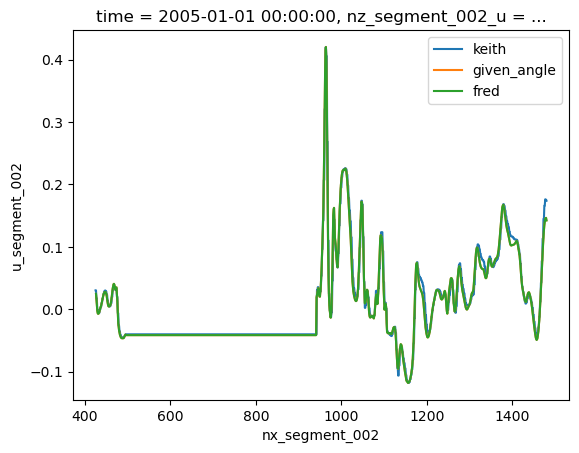

In [17]:
forcing_data_keith.u_segment_002[0][0].plot(label = "keith")
forcing_data_given_angle.u_segment_002[0][0].plot(label="given_angle")
forcing_data_fred.u_segment_002[0][0].plot(label="fred")
plt.legend()

In [ ]:
(forcing_data_fred.u_segment_002[0][0].values - forcing_data_given_angle.u_segment_002[0][0].values)

-3.9317761207613026e-07